[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Naviden/Introduction-to-XAI/blob/main/Practice/Instructor/Core_XAI_Solutions.ipynb)

[Colab setup: dependencies and repository files](https://github.com/Naviden/Introduction-to-XAI/blob/main/docs/REPRODUCIBILITY.md#google-colab)

**Validated reading copy.** Run the [source notebook](../../../../Practice/Instructor/Core_XAI_Solutions.ipynb) in its original directory. This snapshot includes checked outputs; source SHA-256: `6a10441c882c67b369073f40a7e221ba82ebd3940fcf45ab5715bc0e15cad227`. Timings describe this recorded environment, not a performance guarantee.

# Instructor solutions — core XAI exercises

Reference solutions for [the student notebook](../../../../Practice/Core_XAI_Exercises.ipynb). Students should attempt the exercises first. These examples are generated data and fictional candidates, not participant-study results. Install `requirements-tabular.txt`; no downloads or optional explainer packages are needed.

See the [rubric](../../../../Practice/Instructor/Core_XAI_Rubric.md) for interpretation requirements. Matching one seeded number is insufficient without the correct target, units and limitations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer

SEED = 42
rng = np.random.default_rng(SEED)
signal = rng.normal(size=600)
X = pd.DataFrame({'signal': signal, 'proxy': signal + rng.normal(scale=0.08, size=600),
                  'context': rng.normal(size=600)})
latent_logit = 1.5 * X.signal - 0.5 * X.proxy + np.sin(2 * X.context) + 0.3
y = pd.Series(rng.binomial(1, expit(latent_logit)), name='class_1')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
assert set(X_train.index).isdisjoint(X_test.index)
features = X.columns.tolist()
additive = Pipeline([
    ('basis', ColumnTransformer([(f'term_{j}', SplineTransformer(n_knots=4, degree=3, knots='quantile', include_bias=False), [name])
                                 for j, name in enumerate(features)])),
    ('classifier', LogisticRegression(C=0.7, max_iter=2000, random_state=SEED)),
])
additive.fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=80, max_depth=4, min_samples_leaf=8, n_jobs=2, random_state=SEED)
forest.fit(X_train, y_train)
query = X_test.iloc[[0]]
print('Synthetic data only; class 1 is the explained output.')
display(pd.Series({'additive_test_AUC': roc_auc_score(y_test, additive.predict_proba(X_test)[:,1]),
                   'forest_test_AUC': roc_auc_score(y_test, forest.predict_proba(X_test)[:,1])}))

Synthetic data only; class 1 is the explained output.


additive_test_AUC    0.797783
forest_test_AUC      0.794150
dtype: float64

## Exercise 1 — additive model units and exact reconstruction (30 points)

The fitted spline classifier has one term per original feature and a logistic link. Recover each term's contribution from `additive.named_steps['basis'].output_indices_` and the fitted logistic coefficients. Center terms over **training rows only**, adding their means to the intercept.

1. Reconstruct the selected case's logit from the centered intercept and three terms; verify it against `decision_function`.
2. Apply the sigmoid and verify the class-1 probability. Plot the three centered contributions with correctly labeled units.
3. Explain why summing contributions in log-odds is not the same as summing changes in probability. Is `sigmoid(mean(logit))` generally the same as `mean(probability)`?
4. Transfer the reasoning to binary EBM: what do its intercept and evaluated term scores sum to? If an EBM contains a pairwise interaction term, may every displayed term still be described as a function of one input?

**Deliverable:** code checks, one contribution plot, and a short interpretation that separates exact model decomposition from causal explanation. Do not assume that this spline implementation is the EBM algorithm.

Centered intercept 0.3507 + terms 0.6010 = logit 0.9517
Probability = sigmoid(logit) = 0.7215


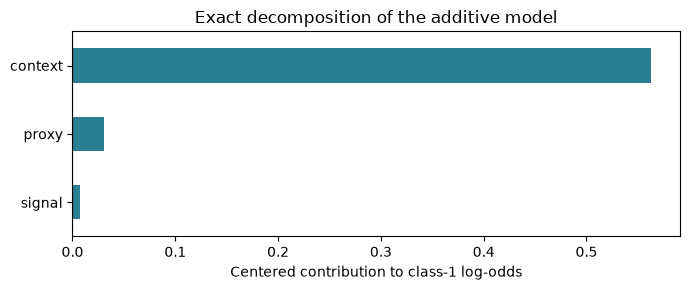

sigmoid_of_mean_training_logit    0.586797
mean_training_probability         0.573301
dtype: float64

In [2]:
basis = additive.named_steps['basis']
coefficients = additive.named_steps['classifier'].coef_[0]
blocks = [basis.output_indices_[f'term_{j}'] for j in range(len(features))]
def raw_terms(frame):
    transformed = basis.transform(frame)
    return np.column_stack([transformed[:, block] @ coefficients[block] for block in blocks])

training_means = raw_terms(X_train).mean(axis=0)
centered_intercept = float(additive.named_steps['classifier'].intercept_[0] + training_means.sum())
for frame in [X_train, X_test]:
    reconstruction = centered_intercept + (raw_terms(frame)-training_means).sum(axis=1)
    np.testing.assert_allclose(reconstruction, additive.decision_function(frame), atol=1e-10)
    np.testing.assert_allclose(expit(reconstruction), additive.predict_proba(frame)[:,1], atol=1e-10)
query_terms = pd.Series(raw_terms(query)[0]-training_means, index=features)
query_logit = centered_intercept + query_terms.sum()
print(f'Centered intercept {centered_intercept:.4f} + terms {query_terms.sum():.4f} = logit {query_logit:.4f}')
print(f'Probability = sigmoid(logit) = {expit(query_logit):.4f}')
fig, ax = plt.subplots(figsize=(7, 3))
query_terms.sort_values().plot.barh(ax=ax, color='#287D8E')
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(xlabel='Centered contribution to class-1 log-odds', title='Exact decomposition of the additive model')
fig.tight_layout()
plt.show()
display(pd.Series({'sigmoid_of_mean_training_logit': expit(additive.decision_function(X_train).mean()),
                   'mean_training_probability': additive.predict_proba(X_train)[:,1].mean()}))

The sigmoid is nonlinear, so it must be applied **after** summing logit terms. Its value at a mean is not generally the mean of its values. Centering changes the presentation of terms and intercept while preserving every prediction.

For a binary logistic-link EBM, the intercept plus evaluated term scores likewise gives a logit. Apply its link inverse to obtain probability. A term can be an interaction over two or more inputs, even though the final score is additive over terms. Neither coefficient/curve readability nor exact reconstruction makes a term causal. This notebook fits a spline additive model, not EBM.

## Exercise 2 — randomness, correlated features and masking (35 points)

Keep the fitted forest and test set fixed.

1. Run held-out ROC-AUC permutation importance using five different shuffle seeds. Report means and variation, stating exactly what the variation measures.
2. Compare shuffling `signal` alone with shuffling the pair (`signal`, `proxy`) together using the **same row permutation**. Why does the latter preserve their mutual relationship?
3. Define an illustrative support check using the training 99th percentile of `abs(signal − proxy)`. Measure the fraction exceeding it in the original test set, independently shuffled data, and jointly shuffled data. This is a diagnostic for the designed relationship, not a general out-of-distribution detector.
4. Explain why a small permutation score for one correlated feature does not establish irrelevance, and why neither shuffle experiment identifies a causal effect.

**Deliverable:** a summary table/plot, a support-check table and a statement distinguishing shuffle variability from a confidence interval over future populations.

,mean_AUC_loss,SD_of_five_run_means
signal,0.068358,0.013635
proxy,0.043583,0.011815
context,0.054444,0.009792


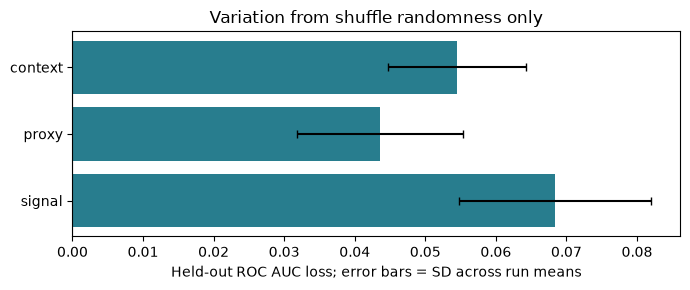

,ROC_AUC,fraction_outside_relationship_band,AUC_loss_from_original
condition,,,
original test,0.794150,0.020000,0.000000
signal shuffled alone,0.699491,0.906667,0.094658
signal + proxy shuffled jointly,0.528888,0.020000,0.265262


In [3]:
seeds = [7, 11, 19, 23, 29]
importance_runs = []
for seed in seeds:
    result = permutation_importance(forest, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=seed)
    importance_runs.append(result.importances_mean)
importance_runs = np.asarray(importance_runs)
summary = pd.DataFrame({'mean_AUC_loss': importance_runs.mean(axis=0),
                        'SD_of_five_run_means': importance_runs.std(axis=0, ddof=1)}, index=features)
display(summary)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(features, summary.mean_AUC_loss, xerr=summary.SD_of_five_run_means, color='#287D8E', capsize=3)
ax.axvline(0, color='0.4', linewidth=0.8)
ax.set(xlabel='Held-out ROC AUC loss; error bars = SD across run means', title='Variation from shuffle randomness only')
fig.tight_layout()
plt.show()

order = np.random.default_rng(SEED).permutation(len(X_test))
independent = X_test.copy()
independent['signal'] = X_test['signal'].to_numpy()[order]
joint = X_test.copy()
joint[['signal', 'proxy']] = X_test[['signal', 'proxy']].to_numpy()[order]
np.testing.assert_allclose((joint.signal-joint.proxy).to_numpy(), (X_test.signal-X_test.proxy).to_numpy()[order])
cutoff = float(np.quantile(np.abs(X_train.signal-X_train.proxy), 0.99))
baseline_auc = roc_auc_score(y_test, forest.predict_proba(X_test)[:,1])
mask_rows = []
for name, frame in [('original test', X_test), ('signal shuffled alone', independent), ('signal + proxy shuffled jointly', joint)]:
    mask_rows.append({'condition': name, 'ROC_AUC': roc_auc_score(y_test, forest.predict_proba(frame)[:,1]),
                      'fraction_outside_relationship_band': float((np.abs(frame.signal-frame.proxy) > cutoff).mean())})
mask_summary = pd.DataFrame(mask_rows).set_index('condition')
mask_summary['AUC_loss_from_original'] = baseline_auc-mask_summary.ROC_AUC
display(mask_summary)
assert mask_summary.loc['signal shuffled alone', 'fraction_outside_relationship_band'] > mask_summary.loc['signal + proxy shuffled jointly', 'fraction_outside_relationship_band']

The variation shown comes from shuffle seeds with one fixed fitted model and test set. It does not capture training-sample uncertainty, model-selection uncertainty or future-data shift.

Joint shuffling preserves the observed relation within the pair but breaks the pair's association with outcomes and other features. It asks about the pair's predictive information as a group. Single-feature shuffling can both conceal redundancy and create implausible combinations; the direction of its effect is not universally guaranteed. The support-band check is intentionally tailored to the known synthetic dependence. Neither intervention on a table is a causal intervention in a data-generating system.

## Exercise 3 — counterfactual validity is more than a prediction flip (35 points)

Use the fictional classifier and candidate pool below. The target is class 1 under a probability threshold of 0.5. `prior_score` records history and is immutable. `study_hours` may only increase; `commute_hours` may only decrease. All values must stay within the declared bounds.

1. Check prediction validity, immutability, bounds and allowed directions **separately** for every candidate. A candidate is admissible only if all checks pass.
2. Among admissible candidates, rank normalized L1 distance from the original, dividing each absolute change by its allowed range width. State that this finds the closest **provided** candidate under a chosen metric, not a globally minimal recourse.
3. Report pairwise normalized L1 distance between the admissible candidates as a simple diversity description. Explain why diversity alone is insufficient.
4. Describe one assumption required to turn these hypothetical changes into a real action plan. Explain why satisfying this toy model's constraints does not prove real-world feasibility or causal benefit.

In [4]:
# A deliberately fictional course-completion classifier; not an intervention model.
def completion_probability(frame):
    return expit(-3 + 0.7 * frame['study_hours'] + 0.2 * frame['prior_score'] - 0.6 * frame['commute_hours'])

original = pd.Series({'study_hours': 2., 'prior_score': 2., 'commute_hours': 2.})
candidates = pd.DataFrame([
    [6., 2., 1.], [7., 2., 2.], [2., 20., 2.],
    [30., 2., 2.], [2., 2., 1.], [10., 2., 3.],
], columns=original.index, index=['candidate_A', 'candidate_B', 'candidate_C', 'candidate_D', 'candidate_E', 'candidate_F'])
lower_bounds = pd.Series({'study_hours': 0., 'prior_score': 0., 'commute_hours': 0.})
upper_bounds = pd.Series({'study_hours': 12., 'prior_score': 10., 'commute_hours': 4.})
print('Original probability:', float(completion_probability(original.to_frame().T).iloc[0]))
display(candidates)

Original probability: 0.08317269649392235


,study_hours,prior_score,commute_hours
candidate_A,6.0,2.0,1.0
candidate_B,7.0,2.0,2.0
candidate_C,2.0,20.0,2.0
candidate_D,30.0,2.0,2.0
candidate_E,2.0,2.0,1.0
candidate_F,10.0,2.0,3.0


In [5]:
probabilities = completion_probability(candidates)
checks = pd.DataFrame(index=candidates.index)
checks['target_prediction'] = probabilities >= 0.5
checks['immutable_ok'] = np.isclose(candidates.prior_score, original.prior_score)
checks['bounds_ok'] = ((candidates >= lower_bounds) & (candidates <= upper_bounds)).all(axis=1)
checks['direction_ok'] = (candidates.study_hours >= original.study_hours) & (candidates.commute_hours <= original.commute_hours)
checks['admissible'] = checks.all(axis=1)
checks['probability'] = probabilities
checks['normalized_L1'] = (np.abs(candidates-original)/(upper_bounds-lower_bounds)).sum(axis=1)
display(checks)
assert set(checks.index[checks.admissible]) == {'candidate_A', 'candidate_B'}
closest = checks.loc[checks.admissible].normalized_L1.idxmin()
print('Closest provided admissible candidate under this scaling:', closest)
assert closest == 'candidate_B'
valid_candidates = candidates.loc[checks.admissible]
normalized = valid_candidates/(upper_bounds-lower_bounds)
diversity = np.abs(normalized.iloc[0]-normalized.iloc[1]).sum()
print(f'Pairwise normalized L1 distance between the two admissible candidates: {diversity:.4f}')
assert diversity > 0

,target_prediction,immutable_ok,bounds_ok,direction_ok,admissible,probability,normalized_L1
candidate_A,True,True,True,True,True,0.731059,0.583333
candidate_B,True,True,True,True,True,0.750260,0.416667
candidate_C,True,False,False,True,False,0.768525,1.800000
candidate_D,True,True,False,True,False,1.000000,2.333333
candidate_E,False,True,True,True,False,0.141851,0.250000
candidate_F,True,True,True,False,False,0.930862,0.916667


Closest provided admissible candidate under this scaling: candidate_B
Pairwise normalized L1 distance between the two admissible candidates: 0.3333


A prediction flip is only one column: C changes immutable history and exceeds its bounds; D exceeds the study-hours bound; E does not flip; F increases commuting when only decreases were allowed. A and B satisfy the declared checks. B is closest under this particular normalization; there is no proof that it is the globally closest feasible change or that this distance captures a person's costs.

The classifier is an association-based hypothetical function. Real recourse would need information about achievable changes, dependencies, costs, intervention effects and persistence over time. Diverse candidate rows do not supply that information.

## References

- [Intrinsic-model comparison](../../../../Tools/InterpretableModels_examples/Interpretable_Models_Comparison.ipynb).
- [Scikit-learn permutation-importance guidance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [InterpretML EBM documentation](https://interpret.ml/docs/ebm.html).
- [DiCE's constraint examples](https://interpret.ml/DiCE/notebooks/DiCE_with_private_data.html) illustrate that search constraints must be chosen explicitly; they do not establish causality.